# import libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('ggplot')

# Load all datasets

In [2]:
train = pd.read_csv("sales_project/train.csv")
test = pd.read_csv("sales_project/test.csv")
stores = pd.read_csv("sales_project/stores.csv")
transactions = pd.read_csv("sales_project/transactions.csv")
oil = pd.read_csv("sales_project/oil.csv")
holidays = pd.read_csv("sales_project/holidays_events.csv")

# Check Dataset Shapes

In [3]:
print("Train:", train.shape)
print("Test:", test.shape)
print("Stores:", stores.shape)
print("Transactions:", transactions.shape)
print("Oil:", oil.shape)
print("Holidays:", holidays.shape)

Train: (3000888, 6)
Test: (28512, 5)
Stores: (54, 5)
Transactions: (83488, 3)
Oil: (1218, 2)
Holidays: (350, 6)


# Inspect Main Dataset

In [4]:
train.head()

,id,date,store_nbr,family,sales,onpromotion
0,0,2013-01-01,1,AUTOMOTIVE,0.0,0
1,1,2013-01-01,1,BABY CARE,0.0,0
2,2,2013-01-01,1,BEAUTY,0.0,0
3,3,2013-01-01,1,BEVERAGES,0.0,0
4,4,2013-01-01,1,BOOKS,0.0,0


In [5]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3000888 entries, 0 to 3000887
Data columns (total 6 columns):
 #   Column       Dtype  
---  ------       -----  
 0   id           int64  
 1   date         object 
 2   store_nbr    int64  
 3   family       object 
 4   sales        float64
 5   onpromotion  int64  
dtypes: float64(1), int64(3), object(2)
memory usage: 137.4+ MB


In [6]:
train.describe()

,id,store_nbr,sales,onpromotion
count,3.000888e+06,3.000888e+06,3.000888e+06,3.000888e+06
mean,1.500444e+06,2.750000e+01,3.577757e+02,2.602770e+00
std,8.662819e+05,1.558579e+01,1.101998e+03,1.221888e+01
min,0.000000e+00,1.000000e+00,0.000000e+00,0.000000e+00
25%,7.502218e+05,1.400000e+01,0.000000e+00,0.000000e+00
50%,1.500444e+06,2.750000e+01,1.100000e+01,0.000000e+00
75%,2.250665e+06,4.100000e+01,1.958473e+02,0.000000e+00
max,3.000887e+06,5.400000e+01,1.247170e+05,7.410000e+02


# Check Missing Values

In [7]:
train.isnull().sum()

id             0
date           0
store_nbr      0
family         0
sales          0
onpromotion    0
dtype: int64

In [8]:
oil.isnull().sum()

date           0
dcoilwtico    43
dtype: int64

In [9]:
transactions.isnull().sum()

date            0
store_nbr       0
transactions    0
dtype: int64

# Convert Dates

In [10]:
train['date'] = pd.to_datetime(train['date'])
test['date'] = pd.to_datetime(test['date'])
transactions['date'] = pd.to_datetime(transactions['date'])
oil['date'] = pd.to_datetime(oil['date'])
holidays['date'] = pd.to_datetime(holidays['date'])

# Create Daily Sales Dataset

In [11]:
daily_sales = train.groupby('date')['sales'].sum().reset_index()

daily_sales.head()

,date,sales
0,2013-01-01,2511.618999
1,2013-01-02,496092.417944
2,2013-01-03,361461.231124
3,2013-01-04,354459.677093
4,2013-01-05,477350.121229


# Plot Daily Sales

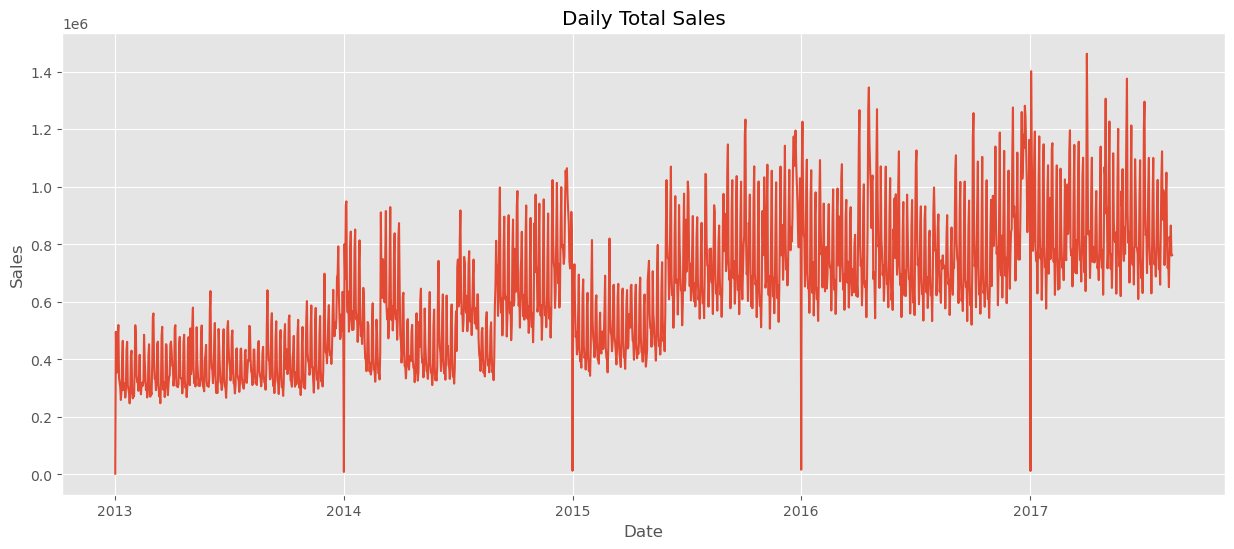

In [12]:
plt.figure(figsize=(15,6))

plt.plot(
    daily_sales['date'],
    daily_sales['sales']
)

plt.title("Daily Total Sales")
plt.xlabel("Date")
plt.ylabel("Sales")

plt.show()

# Check Trend

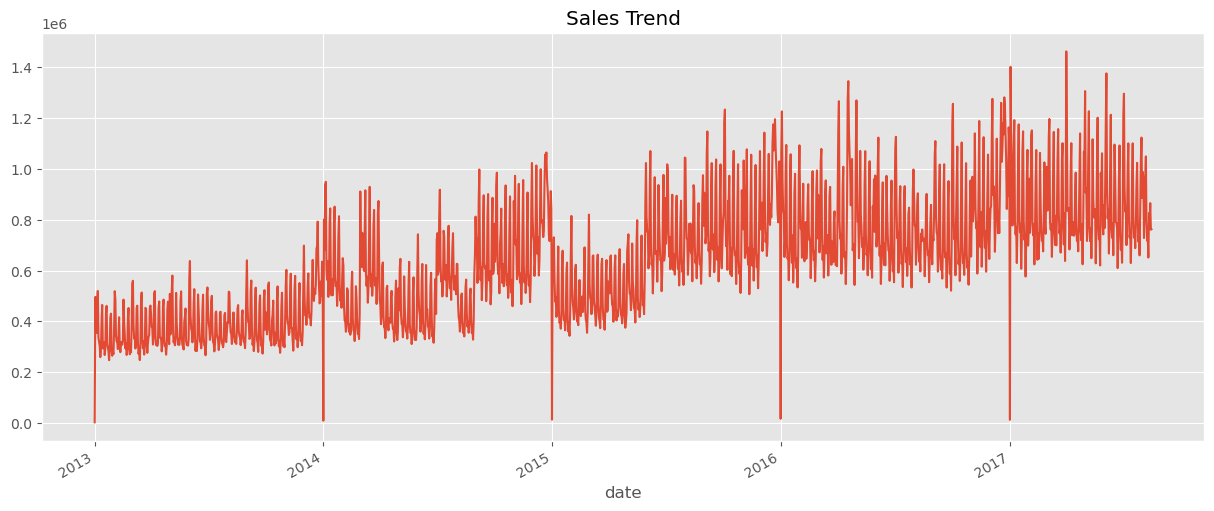

In [13]:
daily_sales.set_index('date', inplace=True)

daily_sales['sales'].plot(
    figsize=(15,6),
    title="Sales Trend"
)

plt.show()

# Time Series Decomposition

In [14]:
from statsmodels.tsa.seasonal import seasonal_decompose

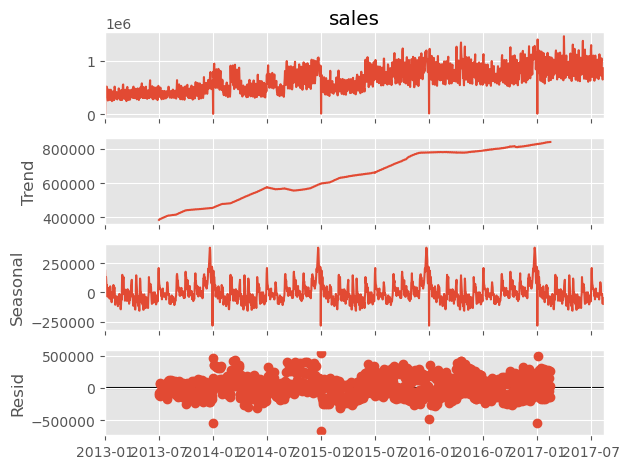

In [15]:
decomposition = seasonal_decompose(
    daily_sales['sales'],
    model='additive',
    period=365
)

decomposition.plot()
plt.show()

# ADF Test (Stationarity)

In [16]:
from statsmodels.tsa.stattools import adfuller
result = adfuller(
    daily_sales['sales']
)

print("ADF Statistic:", result[0])
print("P-value:", result[1])

ADF Statistic: -2.616195748604857
P-value: 0.08969592175787466


# Differencing

In [17]:
daily_sales['sales_diff'] = (
    daily_sales['sales'].diff()
)
daily_sales = daily_sales.dropna()

In [18]:
result = adfuller(
    daily_sales['sales_diff']
)

print("P-value:", result[1])

P-value: 4.573768417348021e-21


# ACF & PACF

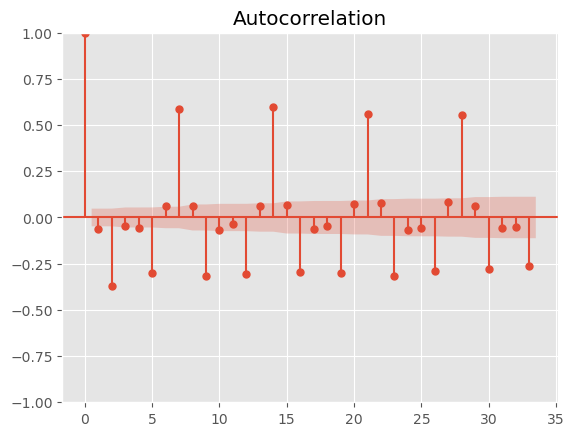

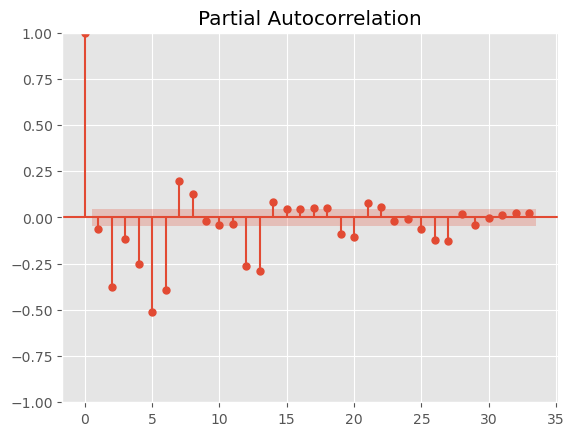

In [19]:
from statsmodels.graphics.tsaplots import (
    plot_acf,
    plot_pacf
)
plot_acf(
    daily_sales['sales_diff']
)

plt.show()
plot_pacf(
    daily_sales['sales_diff']
)

plt.show()

# Train/Test Split

In [20]:
train_size = int(
    len(daily_sales)*0.8
)

train_data = daily_sales.iloc[:train_size]

test_data = daily_sales.iloc[train_size:]

In [21]:
print(train_data.shape)
print(test_data.shape)

(1346, 2)
(337, 2)


# ARIMA Model

In [22]:
from statsmodels.tsa.arima.model import ARIMA
model = ARIMA(
    train_data['sales'],
    order=(5,1,2)
)

model_fit = model.fit()
forecast = model_fit.forecast(
    steps=len(test_data)
)

C:\ProgramData\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
C:\ProgramData\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
C:\ProgramData\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
C:\ProgramData\anaconda3\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:966: UserWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  warn('Non-stationary starting autoregressive pa

# Evaluate ARIMA

In [30]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error
)
mae = mean_absolute_error(
    test_data['sales'],
    forecast
)

rmse = np.sqrt(
    mean_squared_error(
        test_data['sales'],
        forecast
    )
)

print("MAE:", mae)
print("RMSE:", rmse)

MAE: 135576.71754622192
RMSE: 187887.16204585638


# Install Prophet

In [31]:
%pip install prophet

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.1.1
[notice] To update, run: python.exe -m pip install --upgrade pip


# Prepare Prophet Dataset

In [32]:
prophet_df = train.copy()

prophet_df['date'] = pd.to_datetime(prophet_df['date'])

prophet_df = (
    prophet_df
    .groupby('date')['sales']
    .sum()
    .reset_index()
)

prophet_df.columns = ['ds','y']

prophet_df.head()


,ds,y
0,2013-01-01,2511.618999
1,2013-01-02,496092.417944
2,2013-01-03,361461.231124
3,2013-01-04,354459.677093
4,2013-01-05,477350.121229


# Prepare Holidays

In [33]:
holiday_df = holidays.copy()

holiday_df = holiday_df[
    ['date','type']
]

holiday_df.columns = [
    'ds',
    'holiday'
]

holiday_df['ds'] = pd.to_datetime(
    holiday_df['ds']
)

holiday_df.head()

,ds,holiday
0,2012-03-02,Holiday
1,2012-04-01,Holiday
2,2012-04-12,Holiday
3,2012-04-14,Holiday
4,2012-04-21,Holiday


# Create Prophet Model

In [34]:
from prophet import Prophet

model = Prophet(
    holidays=holiday_df,
    yearly_seasonality=True,
    weekly_seasonality=True,
    daily_seasonality=False,
    changepoint_prior_scale=0.05
)

# Add Custom Monthly Seasonality

In [35]:
model.add_seasonality(
    name='monthly',
    period=30.5,
    fourier_order=5
)

# Train Prophet

In [36]:
model.fit(prophet_df)

18:28:11 - cmdstanpy - INFO - Chain [1] start processing
18:28:49 - cmdstanpy - INFO - Chain [1] done processing


# Create Future Dates
90-Day Forecast

In [37]:
future = model.make_future_dataframe(
    periods=90
)

future.tail()

,ds
1769,2017-11-09
1770,2017-11-10
1771,2017-11-11
1772,2017-11-12
1773,2017-11-13


# Generate Forecast

In [38]:
forecast = model.predict(
    future
)

forecast.head()

,ds,trend,yhat_lower,yhat_upper,trend_lower,trend_upper,Additional,Additional_lower,Additional_upper,Bridge,...,weekly,weekly_lower,weekly_upper,yearly,yearly_lower,yearly_upper,multiplicative_terms,multiplicative_terms_lower,multiplicative_terms_upper,yhat
0,2013-01-01,338135.734022,284805.646560,551404.259180,338135.734022,338135.734022,0.0,0.0,0.0,0.0,...,-66735.667518,-66735.667518,-66735.667518,90978.453671,90978.453671,90978.453671,0.0,0.0,0.0,417862.259821
1,2013-01-02,338460.794150,295459.717109,555749.679383,338460.794150,338460.794150,0.0,0.0,0.0,0.0,...,-43264.683707,-43264.683707,-43264.683707,81784.785264,81784.785264,81784.785264,0.0,0.0,0.0,419833.541000
2,2013-01-03,338785.854279,174524.603627,426341.312612,338785.854279,338785.854279,0.0,0.0,0.0,0.0,...,-131442.063162,-131442.063162,-131442.063162,72687.326844,72687.326844,72687.326844,0.0,0.0,0.0,305829.752241
3,2013-01-04,339110.914408,227878.079412,478992.813432,339110.914408,339110.914408,0.0,0.0,0.0,0.0,...,-59392.321132,-59392.321132,-59392.321132,63817.070082,63817.070082,63817.070082,0.0,0.0,0.0,354560.643928
4,2013-01-05,339435.974536,354171.124277,615990.417332,339435.974536,339435.974536,0.0,0.0,0.0,0.0,...,133538.869850,133538.869850,133538.869850,55294.323435,55294.323435,55294.323435,0.0,0.0,0.0,487703.303902


# Forecast Visualization

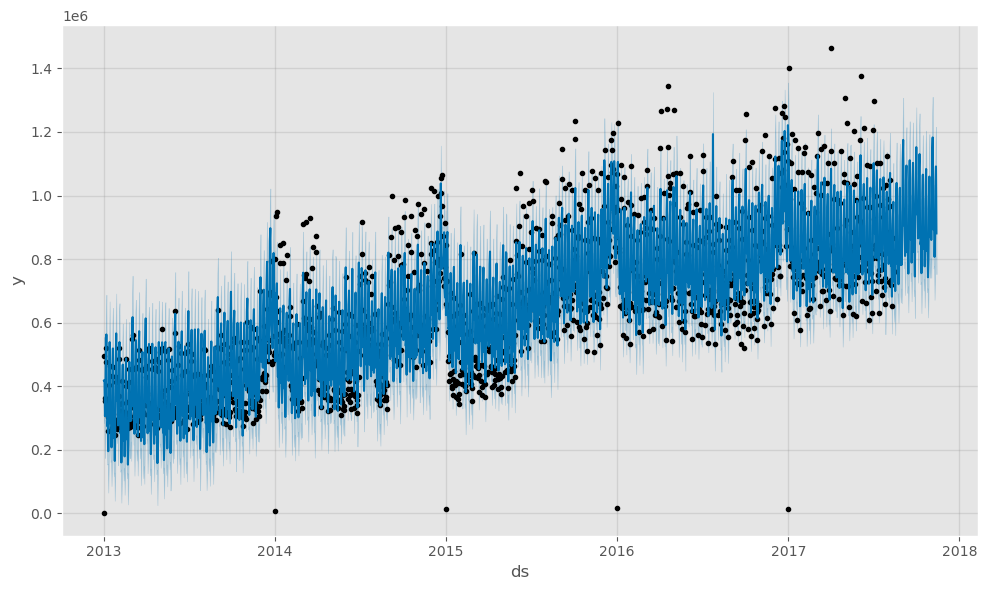

In [39]:
fig = model.plot(
    forecast
)

# Changepoints Visualization

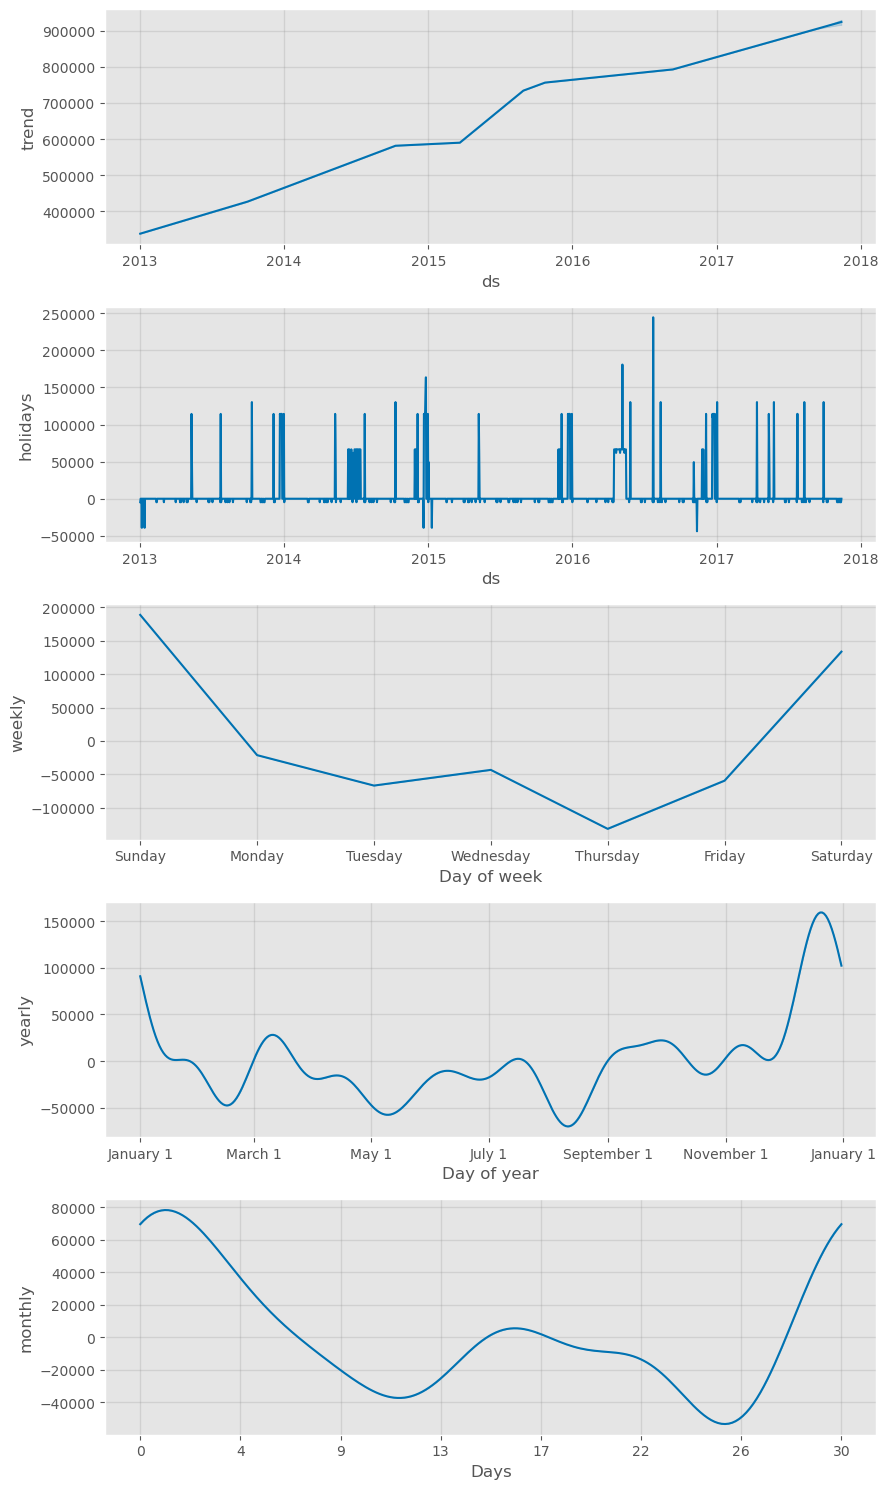

In [40]:
fig2 = model.plot_components(
    forecast
)

# Display Changepoints

In [41]:
model.changepoints

54     2013-02-24
108    2013-04-19
162    2013-06-12
215    2013-08-04
269    2013-09-27
323    2013-11-20
377    2014-01-14
431    2014-03-09
485    2014-05-02
538    2014-06-24
592    2014-08-17
646    2014-10-10
700    2014-12-03
754    2015-01-27
808    2015-03-22
861    2015-05-14
915    2015-07-07
969    2015-08-30
1023   2015-10-23
1077   2015-12-16
1131   2016-02-09
1184   2016-04-02
1238   2016-05-26
1292   2016-07-19
1346   2016-09-11
Name: ds, dtype: datetime64[ns]

# Train/Test Split For Prophet

In [42]:
split_index = int(
    len(prophet_df)*0.8
)

train_prophet = prophet_df.iloc[
    :split_index
]

test_prophet = prophet_df.iloc[
    split_index:
]

# Train Prophet on Train Data

In [43]:
prophet_model = Prophet(
    holidays=holiday_df,
    yearly_seasonality=True,
    weekly_seasonality=True
)

prophet_model.fit(
    train_prophet
)

18:29:39 - cmdstanpy - INFO - Chain [1] start processing
18:29:39 - cmdstanpy - INFO - Chain [1] done processing


# Forecast Test Period

In [44]:
future_test = prophet_model.make_future_dataframe(
    periods=len(test_prophet)
)

forecast_test = prophet_model.predict(
    future_test
)

# Extract Predictions

In [45]:
pred = forecast_test[
    ['ds','yhat']
]

pred = pred.tail(
    len(test_prophet)
)

pred.head()

,ds,yhat
1347,2016-09-12,815274.063860
1348,2016-09-13,772522.505146
1349,2016-09-14,792070.119449
1350,2016-09-15,715829.497339
1351,2016-09-16,776387.245257


# RMSE

In [46]:
from sklearn.metrics import mean_squared_error
import numpy as np

rmse_prophet = np.sqrt(
    mean_squared_error(
        test_prophet['y'],
        pred['yhat']
    )
)

print(
    "Prophet RMSE:",
    rmse_prophet
)

Prophet RMSE: 178442.57114133437


# MAE

In [47]:
from sklearn.metrics import mean_absolute_error

mae_prophet = mean_absolute_error(
    test_prophet['y'],
    pred['yhat']
)

print(
    "Prophet MAE:",
    mae_prophet
)

Prophet MAE: 137355.34318987918


# MAPE

In [48]:
def mape(actual,pred):
    return np.mean(
        np.abs(
            (actual-pred)/actual
        )
    )*100

mape_prophet = mape(
    test_prophet['y'],
    pred['yhat']
)

print(
    "Prophet MAPE:",
    mape_prophet
)

Prophet MAPE: 42.63007024391855


In [49]:
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
import numpy as np

mae_arima = mean_absolute_error(
    test_data['sales'],
    arima_pred
)

rmse_arima = np.sqrt(
    mean_squared_error(
        test_data['sales'],
        arima_pred
    )
)

def mape(actual,pred):
    return np.mean(
        np.abs((actual-pred)/actual)
    )*100

mape_arima = mape(
    test_data['sales'],
    arima_pred
)

print("ARIMA MAE:", mae_arima)
print("ARIMA RMSE:", rmse_arima)
print("ARIMA MAPE:", mape_arima)

NameError: name 'arima_pred' is not defined

# Compare With ARIMA

In [51]:
print('arima_pred' in globals())

False


In [52]:
from statsmodels.tsa.arima.model import ARIMA

model = ARIMA(
    train_data['sales'],
    order=(5,1,2)
)

model_fit = model.fit()

arima_pred = model_fit.forecast(
    steps=len(test_data)
)

C:\ProgramData\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
C:\ProgramData\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
C:\ProgramData\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
C:\ProgramData\anaconda3\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:966: UserWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  warn('Non-stationary starting autoregressive pa

In [53]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

mae_arima = mean_absolute_error(
    test_data['sales'],
    arima_pred
)

rmse_arima = np.sqrt(
    mean_squared_error(
        test_data['sales'],
        arima_pred
    )
)

def mape(actual, pred):
    return np.mean(
        np.abs((actual - pred) / actual)
    ) * 100

mape_arima = mape(
    test_data['sales'],
    arima_pred
)

print("ARIMA MAE:", mae_arima)
print("ARIMA RMSE:", rmse_arima)
print("ARIMA MAPE:", mape_arima)

ARIMA MAE: 135576.71754622192
ARIMA RMSE: 187887.16204585638
ARIMA MAPE: nan


C:\Users\vangapalli sivamani\AppData\Local\Temp\ipykernel_3564\3906225634.py:18: RuntimeWarning: '<' not supported between instances of 'int' and 'Timestamp', sort order is undefined for incomparable objects.
  np.abs((actual - pred) / actual)


In [54]:
comparison = pd.DataFrame({
    "Model":[
        "ARIMA",
        "Prophet"
    ],
    "RMSE":[
        rmse_arima,
        rmse_prophet
    ],
    "MAE":[
        mae_arima,
        mae_prophet
    ],
    "MAPE":[
        mape_arima,
        mape_prophet
    ]
})

comparison

,Model,RMSE,MAE,MAPE
0,ARIMA,187887.162046,135576.717546,NaN
1,Prophet,178442.571141,137355.343190,42.63007


# Best Model

In [55]:
best_model = comparison.loc[
    comparison['RMSE'].idxmin()
]

print(best_model)

Model          Prophet
RMSE     178442.571141
MAE       137355.34319
MAPE          42.63007
Name: 1, dtype: object


# Interactive Plotly Forecast

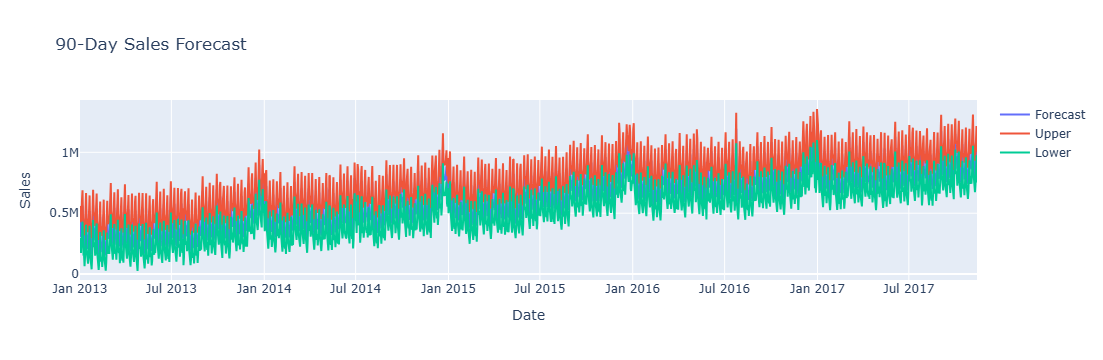

In [56]:
import plotly.graph_objects as go
fig = go.Figure()

fig.add_trace(
    go.Scatter(
        x=forecast['ds'],
        y=forecast['yhat'],
        name='Forecast'
    )
)

fig.add_trace(
    go.Scatter(
        x=forecast['ds'],
        y=forecast['yhat_upper'],
        name='Upper'
    )
)

fig.add_trace(
    go.Scatter(
        x=forecast['ds'],
        y=forecast['yhat_lower'],
        name='Lower'
    )
)

fig.update_layout(
    title="90-Day Sales Forecast",
    xaxis_title="Date",
    yaxis_title="Sales"
)

fig.show()

# Save 90-Day Forecast

In [57]:
future_forecast = forecast.tail(90)

future_forecast.to_csv(
    "future_90_day_forecast.csv",
    index=False
)

# Business Impact Analysis

In [58]:
avg_sales = future_forecast[
    'yhat'
].mean()

print(
    "Average Predicted Daily Sales:",
    round(avg_sales,2)
)

Average Predicted Daily Sales: 913620.48


In [59]:
future_forecast[
    'yhat'
].describe()

count    9.000000e+01
mean     9.136205e+05
std      1.187314e+05
min      6.994285e+05
25%      8.266465e+05
50%      8.791540e+05
75%      1.003504e+06
max      1.182891e+06
Name: yhat, dtype: float64